# DSCI 552 - Homework 3

## Setup

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
sns.set_theme(style="whitegrid")

## Problem 1: Time Series Classification, Part 1

### 1(a) Loading the AReM data

The AReM dataset was downloaded from the UCI Machine Learning Repository and unzipped into an `AReM` folder next to this notebook. The zip contains a nested `AReM` folder, which holds one subfolder per activity (plus two PDFs describing the setup).

In [ ]:
data_dir = Path("AReM") / "AReM"
for item in sorted(data_dir.iterdir()):
    print(item.name)

.DS_Store
bending1
bending2
bendingType.pdf
cycling
lying
sensorsPlacement.pdf
sitting
standing
walking


Each activity folder contains several `datasetN.csv` files. Each file is one instance: 480 readings of 6 time series (`avg_rss12`, `var_rss12`, `avg_rss13`, `var_rss13`, `avg_rss23`, `var_rss23`) plus a time column. The first 4 lines of each file are comments, so they are skipped with `skiprows=4`:

In [ ]:
test_file = data_dir / "cycling" / "dataset1.csv"
df = pd.read_csv(test_file, skiprows =4)
print(df.head())
print(df.shape)

   # Columns: time  avg_rss12  var_rss12  avg_rss13  var_rss13  avg_rss23  \
0                0       32.0       4.85      17.50       3.35      22.50   
1              250       40.5       1.12      14.00       2.24      21.75   
2              500       40.5       2.60      11.33       4.50      18.25   
3              750       34.5       1.50      20.67       2.87      19.00   
4             1000       34.5       1.50      21.25       3.27      18.25   

   var_rss23  
0       3.20  
1       1.30  
2       5.31  
3       2.83  
4       4.38  
(480, 7)


**Data quality check.** Every file is read and checked for the expected shape `(480, 7)` and for missing values. Reading with `usecols=range(7)` keeps only the time column and the 6 series.

In [ ]:
for folder in sorted(data_dir.iterdir()):
    if folder.is_dir():
        for file in sorted(folder.glob("*.csv")):
            num = int(file.stem.removeprefix("dataset"))
            df = pd.read_csv(file, skiprows=4, usecols=range(7))
            if df.shape != (480, 7):
                print("PROBLEM:", folder.name, num, df.shape)
            if df.isna().sum().sum() > 0:
                print("MISSING VALUES:", folder.name, num)

Investigating `sitting/dataset8.csv`, which has 479 rows instead of 480:

In [ ]:
check = pd.read_csv(data_dir / "sitting" / "dataset8.csv", skiprows=4, usecols=range(7))
print(check.columns)
print(check.head(3))
print(check.tail(3))

Index(['# Columns: time', 'avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13',
       'avg_rss23', 'var_rss23'],
      dtype='object')
   # Columns: time  avg_rss12  var_rss12  avg_rss13  var_rss13  avg_rss23  \
0                0      44.00       0.71      18.75       0.43       7.75   
1              250      44.00       0.00      18.50       0.50       8.67   
2              500      43.75       0.83      18.00       0.00       9.67   

   var_rss23  
0       1.30  
1       0.47  
2       0.94  
     # Columns: time  avg_rss12  var_rss12  avg_rss13  var_rss13  avg_rss23  \
476           119250      42.50       0.50      18.00       0.00      15.25   
477           119500      42.50       0.50      18.25       0.43      16.00   
478           119750      42.25       0.43      20.00       0.71      19.00   

     var_rss23  
476       0.43  
477       1.22  
478       1.00  


Readings are 250 ms apart, so any jump other than 250 marks a gap (row 0 appears only because it has no previous row):

In [ ]:
time_col = check.iloc[:, 0]      # first column = time
gaps = time_col.diff()           # difference from the previous row
print(check[gaps != 250])

    # Columns: time  avg_rss12  var_rss12  avg_rss13  var_rss13  avg_rss23  \
0                 0       44.0       0.71      18.75       0.43       7.75   
54            13750       42.0       0.00      18.25       1.79      18.25   

    var_rss23  
0        1.30  
54       2.17  


**Data cleaning notes:**
- **`cycling/dataset14.csv`:** the last line contains an extra field, which made `pd.read_csv` fail. Reading with `usecols=range(7)` keeps only the 7 real columns and ignores the extra value.
- **`sitting/dataset8.csv`:** has 479 readings. The time column jumps from 13250 to 13750, so the reading at time 13500 is missing from the original recording. I kept the file as-is, since one missing value out of 480 has a negligible effect on the summary statistics, and dropping the instance would lose 1 of only 88.

### 1(b) Train/test split

Datasets 1–2 in `bending1` and `bending2`, and datasets 1–3 in every other folder, are test data; all other datasets are training data. Rather than moving files, each instance is labeled with a `split` column when the feature table is built below.

### 1(c)i Common time-domain features

- **Location:** mean (average value), median (middle value, robust to outliers), mode (most frequent value).
- **Spread:** standard deviation and variance (average deviation from the mean), range (max − min), interquartile range (Q3 − Q1, robust to outliers), mean absolute deviation.
- **Order statistics:** minimum, maximum, first quartile (25th percentile), third quartile (75th percentile), other percentiles.
- **Distribution shape:** skewness (asymmetry of the distribution), kurtosis (heaviness of the tails, or how often extreme values occur).
- **Energy/magnitude:** root mean square (RMS), signal energy (sum of squared values), mean absolute value.
- **Temporal (order-dependent):** autocorrelation (similarity of the series to a lagged copy of itself), zero/mean-crossing rate (how often the signal crosses its mean), number of peaks, slope or linear trend, first-difference statistics (e.g., mean absolute change between consecutive points).

All features except the temporal ones give the same value if the readings are shuffled; the temporal features capture how the signal changes over time.

*Source:* O. D. Lara and M. A. Labrador, "A Survey on Human Activity Recognition using Wearable Sensors," *IEEE Communications Surveys & Tutorials*, 2013.

### 1(c)ii Feature extraction

For each of the 88 instances, the minimum, maximum, mean, median, standard deviation, first quartile, and third quartile are computed for each of the 6 time series, giving 42 features. Each row also records the activity, dataset number, and train/test split. Features are used unstandardized.

In [ ]:
rows = []

for folder in sorted(data_dir.iterdir()):
    if folder.is_dir():
        for file in sorted(folder.glob("*.csv")):
            num = int(file.stem.removeprefix("dataset"))
            if folder.name.startswith("bending"):
                if num <= 2:
                    split = "test"
                else:
                    split = "train"
            else:
                if num <= 3:
                    split = "test"
                else:
                    split = "train"

            df = pd.read_csv(file, skiprows=4, usecols=range(7))
            row = {"activity": folder.name, "dataset": num, "split": split}

            series_cols = df.columns[1:7]
            for i, col in enumerate(series_cols, start=1):
                s = df[col]
                row[f"min{i}"] = s.min()
                row[f"max{i}"] = s.max()
                row[f"mean{i}"] = s.mean()
                row[f"median{i}"] = s.median()
                row[f"std{i}"] = s.std()
                row[f"1st_quart{i}"] = s.quantile(0.25)
                row[f"3rd_quart{i}"] = s.quantile(0.75)

            rows.append(row)

features = pd.DataFrame(rows)
print(features.shape)

(88, 45)


In [ ]:
features.head()

Sanity checks: the order statistics should increase from min to max, and the split should have 69 training and 19 test instances.

In [ ]:
cols = ["min1", "1st_quart1", "median1", "3rd_quart1", "max1"]
print(features[cols].head())

    min1  1st_quart1  median1  3rd_quart1   max1
0  37.25       39.25    40.50       42.00  45.00
1  38.00       42.00    42.50       43.67  45.67
2  35.00       43.00    44.33       45.00  47.40
3  33.00       39.15    43.50       45.00  47.75
4  33.00       41.33    41.75       42.75  45.75


In [ ]:
print(features["split"].value_counts())

split
train    69
test     19
Name: count, dtype: int64


### 1(c)iii Standard deviation of each feature and 90% bootstrap confidence intervals

First, the standard deviation of each feature across the 88 instances:

In [ ]:
X = features.drop(columns=["activity", "dataset", "split"])
print(X.shape)

(88, 42)


In [ ]:
feature_std = X.std()
print(feature_std)

min1          9.624011
max1          4.207745
mean1         5.276431
median1       5.386624
std1          1.771282
1st_quart1    6.127846
3rd_quart1    5.031028
min2          0.000000
max2          5.059656
mean2         1.577908
median2       1.413545
std2          0.885875
1st_quart2    0.948434
3rd_quart2    2.131337
min3          2.954516
max3          4.819848
mean3         3.976754
median3       4.009687
std3          0.952011
1st_quart3    4.184148
3rd_quart3    4.153451
min4          0.000000
max4          2.181809
mean4         1.168268
median4       1.148591
std4          0.458612
1st_quart4    0.844919
3rd_quart4    1.555235
min5          6.121205
max5          5.773355
mean5         5.704025
median5       5.844368
std5          1.012358
1st_quart5    6.122142
3rd_quart5    5.563553
min6          0.046101
max6          2.533515
mean6         1.157222
median6       1.089858
std6          0.516968
1st_quart6    0.761542
3rd_quart6    1.526871
dtype: float64


**Bootstrap.** The 88 instances are resampled with replacement 1,000 times; for each resample the standard deviation of every feature is recomputed. The 90% confidence interval is given by the 5th and 95th percentiles of those 1,000 values. Using the loop index as `random_state` makes each resample different but reproducible.

In [ ]:
boot_stds = []

for b in range(1000):
    one_sample = X.sample(n=88, replace=True, random_state=b)
    boot_stds.append(one_sample.std())

boot_stds = pd.DataFrame(boot_stds)
print(boot_stds.shape)

(1000, 42)


In [ ]:
lower = boot_stds.quantile(0.05)
upper = boot_stds.quantile(0.95)

ci_table = pd.DataFrame({
    "std_estimate": feature_std,
    "CI_lower": lower,
    "CI_upper": upper,
})
ci_table.round(3)

`min2` and `min4` have a standard deviation of exactly 0 with a confidence interval of [0, 0]: the minimum of `var_rss12` and `var_rss13` is 0 in every instance, so these two features are constant and carry no information.

### 1(c)iv Selecting the three most important features

To judge which features are useful, I compared how well each separates the activities (boxplots by activity) and how redundant the features are with each other (correlation matrix), using series 1 as an example.

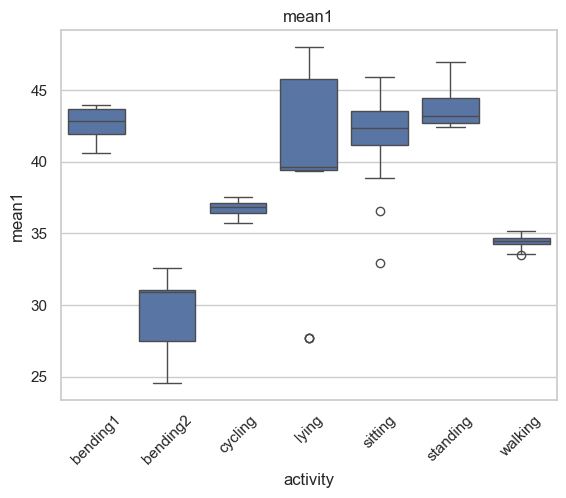

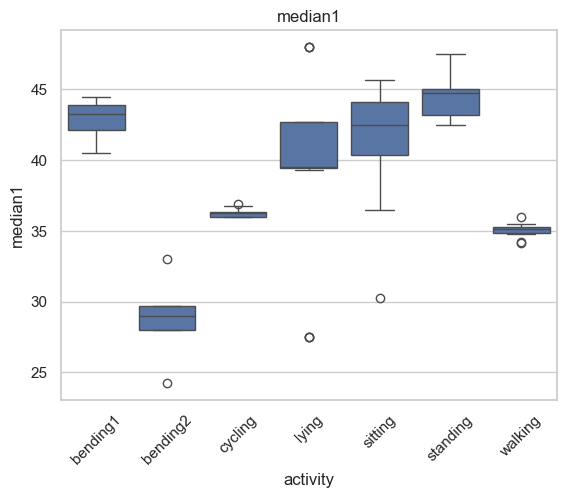

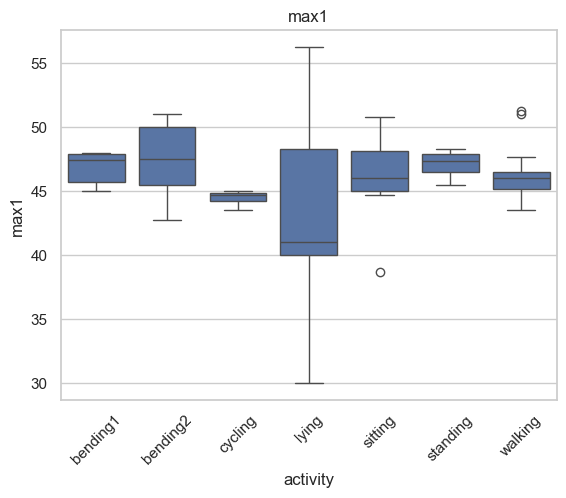

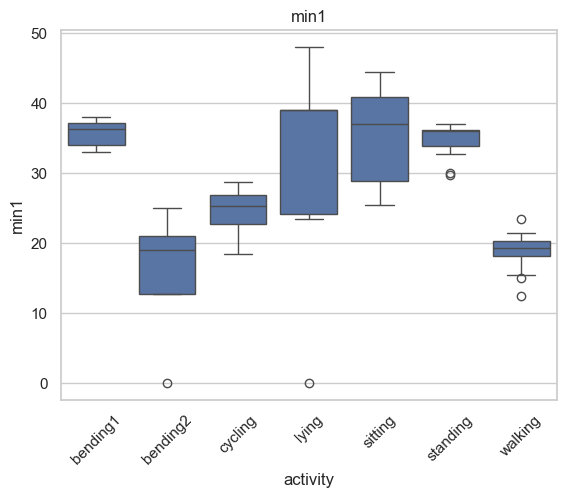

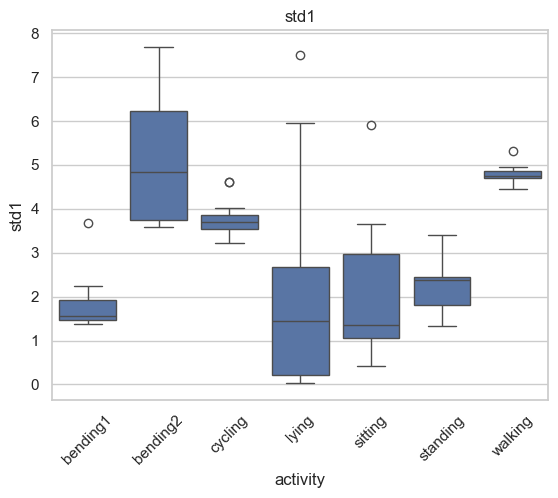

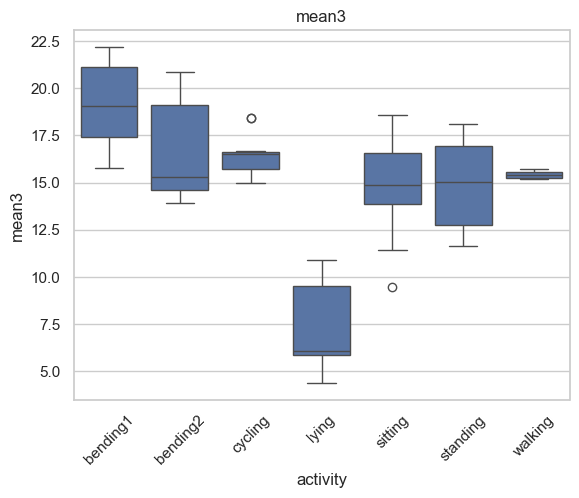

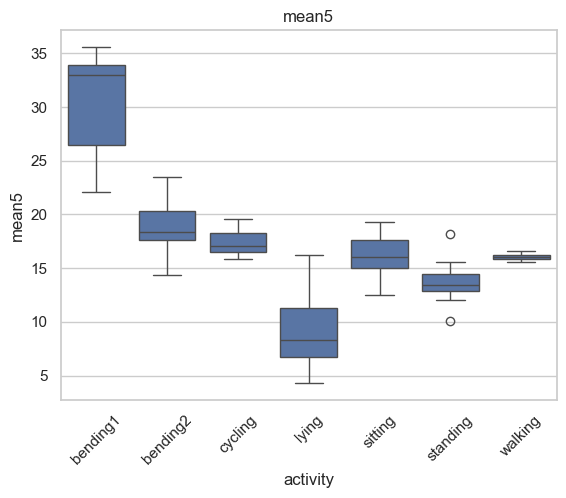

In [ ]:
to_plot = ["mean1", "median1", "max1", "min1", "std1", "mean3", "mean5"]

for f in to_plot:
    sns.boxplot(data=features, x="activity", y=f)
    plt.xticks(rotation=45)
    plt.title(f)
    plt.show()

In [ ]:
cols = ["min1", "max1", "mean1", "median1", "std1", "1st_quart1", "3rd_quart1"]
print(features[cols].corr().round(2))

            min1  max1  mean1  median1  std1  1st_quart1  3rd_quart1
min1        1.00  0.20   0.77     0.72 -0.64        0.77        0.67
max1        0.20  1.00   0.50     0.46  0.31        0.36        0.61
mean1       0.77  0.50   1.00     0.98 -0.45        0.97        0.95
median1     0.72  0.46   0.98     1.00 -0.45        0.97        0.91
std1       -0.64  0.31  -0.45    -0.45  1.00       -0.57       -0.20
1st_quart1  0.77  0.36   0.97     0.97 -0.57        1.00        0.88
3rd_quart1  0.67  0.61   0.95     0.91 -0.20        0.88        1.00


**Choice: min, mean, and max.**

For series 1, mean, median, and the first and third quartiles are highly correlated with each other (r = 0.88–0.98; mean vs. median r = 0.98), so they carry largely the same information about where the series is centered. I kept only the mean from that group to avoid redundancy. Max has low correlation with that group (r = 0.20–0.61) and min is only moderately correlated (r ≈ 0.67–0.77), so they add information about the extremes of the signal. The boxplot of `mean1` shows it separates bending2, cycling, and walking well, while bending1, lying, sitting, and standing overlap, so complementary features are needed. Standard deviation would be a reasonable alternative to min, since it is also weakly correlated with the center features. Finally, `min2` and `min4` have a bootstrap standard deviation of exactly 0 (CI [0, 0]), meaning they are constant across all instances and cannot distinguish activities.

## Problem 2: ISLR 3.7.4

A linear model $Y = \beta_0 + \beta_1 X + \epsilon$ and a cubic model $Y = \beta_0 + \beta_1 X + \beta_2 X^2 + \beta_3 X^3 + \epsilon$ are fit to $n = 100$ observations.

**(a)** The true relationship is linear. The cubic model will have lower (or equal) **training** RSS. It contains the linear model as a special case ($\beta_2 = \beta_3 = 0$), and least squares minimizes training RSS, so the extra terms can only reduce it by fitting some of the noise.

**(b)** The true relationship is linear. We expect the linear model to have lower **test** RSS. Because the truth is linear, the cubic terms do not reduce bias; they only fit noise in the training data, increasing variance and hurting performance on new data. This holds on average, though not necessarily for every sample.

**(c)** The true relationship is non-linear. The cubic model will have lower (or equal) **training** RSS. The argument in (a) does not depend on the true relationship, only on the cubic model containing the linear one.

**(d)** The true relationship is non-linear. There is not enough information to tell which model has lower **test** RSS. If the true relationship is far from linear, the cubic model's reduced bias should give it lower test RSS. If it is close to linear, the cubic model's added variance may outweigh its small reduction in bias, so the linear model could do better.

| Part | True relationship | RSS | Lower RSS |
|---|---|---|---|
| (a) | Linear | Training | Cubic |
| (b) | Linear | Test | Linear (expected) |
| (c) | Non-linear | Training | Cubic |
| (d) | Non-linear | Test | Not enough information |